# Lab: Classification with Bank Marketing Data

---

In this lab you will practice building and evaluating **classification models** using a real bank marketing dataset.

The data comes from direct marketing campaigns conducted by a Portuguese banking institution. The campaigns were based on phone calls, and the classification goal is to predict whether a client will subscribe to a term deposit.

We will use the official `bank.csv` sample from the **UCI Bank Marketing dataset**. It is a 10% random sample of the larger dataset and is useful here because we will train several KNN models while choosing a value of `k`.

**Source:** UCI Machine Learning Repository — Bank Marketing  
https://archive.ics.uci.edu/dataset/222/bank+marketing

**Target:** `y`
- `yes` = client subscribed to a term deposit
- `no` = client did not subscribe

### Data Dictionary

| Variable | Description |
|---|---|
| `age` | Client age |
| `job` | Type of job |
| `marital` | Marital status |
| `education` | Education level |
| `default` | Whether the client has credit in default |
| `balance` | Average yearly account balance, in euros |
| `housing` | Whether the client has a housing loan |
| `loan` | Whether the client has a personal loan |
| `contact` | Contact communication type |
| `day` | Day of the month of the last contact |
| `month` | Month of the last contact |
| `duration` | Duration of the last contact, in seconds |
| `campaign` | Number of contacts performed during the current campaign |
| `pdays` | Days since the client was last contacted in a previous campaign (`-1` means not previously contacted) |
| `previous` | Number of contacts performed before the current campaign |
| `poutcome` | Outcome of the previous marketing campaign |
| `y` | Whether the client subscribed to the term deposit (`yes` / `no`) |

#### Understanding the Bank Marketing Features

Think of each row as describing a client at the time of a contact in the **current marketing campaign**.

##### Timeline

```text
CLIENT INFORMATION — already known
│
├── age        → client's age
├── job        → occupation
├── marital    → marital status
├── education  → education level
├── default    → has credit in default?
├── balance    → account balance
├── housing    → has housing loan?
└── loan       → has personal loan?
│
│
▼
PREVIOUS MARKETING CAMPAIGN(S)
│
├── previous   → number of contacts made BEFORE the current campaign
├── poutcome   → outcome of the previous campaign
│
└── Last contact from a previous campaign
        │
        │
        │  pdays
        │  = number of days since this previous contact
        │
        ▼
CURRENT MARKETING CAMPAIGN
│
├── Current contact is about to take place
│
├── month      → month of the current contact
├── day        → day of the current contact
├── contact    → contact method (e.g. cellular / telephone)
├── campaign   → contact number during this campaign (includes the current contact)
│
│                 Example:
│                 Call 1 → Call 2 → Call 3
│                                      ↑
│                                campaign = 3
│
▼
CURRENT PHONE CALL
│
├── duration   → how long this current contact/call lasted
│
▼
CAMPAIGN OUTCOME
│
└── y          → Did the client subscribe to a term deposit?
    
```

In [245]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import roc_auc_score, roc_curve, RocCurveDisplay
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score

# Import DummyClassifier to calculate the baseline (null) model
from sklearn.dummy import DummyClassifier

# Import logistic regression
from sklearn.linear_model import LogisticRegression


### 1. Download and read in the Bank Marketing data.

Download the UCI Bank Marketing archive and extract `bank.csv`.

Then:

1. Read the CSV into a pandas dataframe.
2. Remember that this file uses `;` as the separator.
3. Display the first five rows.

In [246]:
df = pd.read_csv('bank.csv', sep=';')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


### 2. Conduct an initial exploration of the dataset.

Complete the following:

1. Check the shape of the dataset.
2. Inspect the data types and missing values.
3. Display summary statistics.
4. Check the distribution of the target variable `y`, including percentages.
5. Is this a balanced or imbalanced classification problem? Explain briefly.

In [247]:
df.shape

(4521, 17)

In [248]:
df['default'].unique()

<StringArray>
['no', 'yes']
Length: 2, dtype: str

In [249]:
df.info()
# marital column has 3 unique values, i recommend one-hot encoding
# education column has 4 unique values, idk want to recommend since there is a value called 'unknown'
# [marital (3), default, housing, loan, contact(3)] columns, one-hot encoding (متعثر في السداد)
# [month] columns, ordinal or label encoding 

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB


In [250]:
df.describe(include='number')

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [251]:
df.describe(include= 'object')

C:\Users\TALAL ALOTHMAN\AppData\Local\Temp\ipykernel_15384\3793228563.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include= 'object')


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,4521,4521,4521,4521,4521,4521,4521,4521,4521,4521
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,yes,no,cellular,may,unknown,no
freq,969,2797,2306,4445,2559,3830,2896,1398,3705,4000


In [252]:
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True))

y
no     4000
yes     521
Name: count, dtype: int64
y
no     0.88476
yes    0.11524
Name: proportion, dtype: float64


In [253]:
# Q5)
# imbalance


### 3. Define the business problem and choose an evaluation metric.

Assume the bank wants to use the model to decide **which clients should be prioritized for future marketing calls**.

Answer the following:

1. What does a **False Positive** mean in this business problem? What is the cost of this error?
2. What does a **False Negative** mean? What is the cost of this error?
3. Assume the bank considers both errors important, which metric would you choose?
4. Why might **Accuracy** be misleading for this dataset?

#### Answers

1. it means that our model made a false prediction that the person will subscribe to the term deposit. in this case, we annoyed the client & waste time.  
2. it means that our model made a false prediction that the person will not subscribe to the term deposit. in this case, we'll lose a deal. 
3. 1-recall (% of false negative), 1-percision (% of false positive). F1 combine both metrics in one metric
4. accuracy is misleading since it just shows the % of true predictions u made, it isn't measuring performance of  

### 4. Check for information that would lead to data leakage.

The goal is to prioritize clients **before making the marketing call**.

Review the data dictionary and identify any variable that would only become known after the call has already taken place.

1. Which variable should be removed?
2. Why would keeping it create a data leakage / unrealistic prediction problem?
3. Drop the variable from the dataframe.

#### Answers:

1. [duration, y]
2. 

??

??

In [254]:
# 3. 
df = df.drop(columns='duration')
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4516,33,services,married,secondary,no,-333,yes,no,cellular,30,jul,5,-1,0,unknown,no
4517,57,self-employed,married,tertiary,yes,-3313,yes,yes,unknown,9,may,1,-1,0,unknown,no
4518,57,technician,married,secondary,no,295,no,no,cellular,19,aug,11,-1,0,unknown,no
4519,28,blue-collar,married,secondary,no,1137,no,no,cellular,6,feb,4,211,3,other,no


### 5. Encode binary categorical variables

Complete the following:

1. Identify the predictor columns containing only `yes` and `no`.
2. Map these columns to `0` and `1`.

> This mapping can be done before the train/test split because it follows a fixed rule and does not learn any information from the dataset.

In [255]:
#df[['default', 'housing', 'loan', 'y']].replace(to_replace=['yes', 'not'], value=[1, 0], inplace=True)     # why it didn't work!?
#df[['default', 'housing', 'loan', 'y']] = df[['default', 'housing', 'loan', 'y']].replace({'yes':1, 'no':0}, inplace=True)
#df[['default', 'housing', 'loan', 'y']].astype('int64')
binary_columns = ['default', 'housing', 'loan', "y"]
for i in binary_columns:
    df[i] = df[i].map({'yes': 1, 'no': 0})

### 6. Prepare the target and split the data.

Complete the following:

1. Create `X` and `y`.
2. Split the data into training and testing sets.

In [256]:
X = df[['loan', 'housing', 'default', 'marital', 'job', 'poutcome', 'balance', 'contact', 'campaign', 'pdays', 'previous', 'month', 'education']]
y = df['y']


### 7. Preprocess the training and testing sets

The dataset contains both numerical and categorical variables. Also, there is imbalance in your dataset

#### Part A: Scaling the numerical features

For now, let's transform the numerical ones.

Complete the following:

1. Create a list of numerical columns.
2. Create a `StandardScaler` for the numerical columns.
    - Fit the scaler on the numerical columns of `X_train` only.
    - Use the fitted scaler to transform both `X_train` and `X_test`.
3. Store the scaled numerical values back into their original columns in `X_train` and `X_test`
    - No need to use `.set_output()`
4. Why do we need to scale our data if our model of choice is KNN?


In [257]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=34, stratify=y)

In [258]:
num_cols = X.select_dtypes(include= 'number').columns.to_list()
print(num_cols)


['loan', 'housing', 'default', 'balance', 'campaign', 'pdays', 'previous']


In [259]:
Sscaler = StandardScaler().set_output(transform='pandas')

X_train_num_scaled = Sscaler.fit_transform(X_train[num_cols])
X_train_num_scaled.head()

X_test_num_scaled = Sscaler.transform(X_test[num_cols])
X_test_num_scaled.head()

,loan,housing,default,balance,campaign,pdays,previous
934,-0.421298,0.868711,-0.131935,-0.111998,-0.261447,-0.403029,-0.320713
3676,-0.421298,-1.151131,-0.131935,0.301229,-0.588376,-0.403029,-0.320713
189,-0.421298,0.868711,-0.131935,-0.865063,-0.261447,-0.403029,-0.320713
2262,-0.421298,-1.151131,-0.131935,-0.433654,-0.588376,-0.403029,-0.320713
2729,-0.421298,0.868711,-0.131935,-0.132163,-0.588376,-0.403029,-0.320713


In [260]:
# 3. save them into original X_train & X_test
X_train[num_cols] = X_train_num_scaled
X_train.head()

X_test[num_cols] = X_test_num_scaled
X_test.head()

,loan,housing,default,marital,job,poutcome,balance,contact,campaign,pdays,previous,month,education
934,-0.421298,0.868711,-0.131935,married,management,unknown,-0.111998,unknown,-0.261447,-0.403029,-0.320713,may,secondary
3676,-0.421298,-1.151131,-0.131935,married,services,unknown,0.301229,cellular,-0.588376,-0.403029,-0.320713,aug,secondary
189,-0.421298,0.868711,-0.131935,married,retired,unknown,-0.865063,cellular,-0.261447,-0.403029,-0.320713,jun,secondary
2262,-0.421298,-1.151131,-0.131935,single,management,unknown,-0.433654,cellular,-0.588376,-0.403029,-0.320713,jul,tertiary
2729,-0.421298,0.868711,-0.131935,single,blue-collar,unknown,-0.132163,unknown,-0.588376,-0.403029,-0.320713,may,tertiary


**Q4)**

KNN model relies on calculating the distances between data points. if our features have different scales, the feature with larger numerical value will dominate the distance calculation, which leds to misleading predictions 

#### Part B: Balancing the training data

Regular `SMOTE` creates synthetic observations by interpolating between neighboring observations. This works well for numerical features, but it is not suitable for categorical features.

Instead, we will use **SMOTENC**, a version of SMOTE designed for datasets containing both numerical and categorical features.

We will apply SMOTENC **before One-Hot Encoding**.

**Why?**

- After One-Hot Encoding, one categorical feature such as `job` becomes several binary columns:

    - `job_admin`, `job_student`, `job_retired`, ...
    
- If we used regular SMOTE after One-Hot Encoding, interpolation could create invalid values such as:

    - `job_admin = 0.4`, `job_student = 0.6`

- which do not represent a real category.

- So applying the resampler at this stage allows us to assign the synthetic sample the most common category among the selected minority-class neighbors.

Complete the following:

1. Identify the categorical columns in the training set.
2. Create a `SMOTENC` resampler:
   - specify which columns are categorical
   - use the default value for `k_neighbors`
   - let the minority class size be **50% of the majority class**
3. Apply the `SMOTENC` **only to the training set**.
4. Compare the training target distribution before and after `SMOTENC`.
5. Why should `SMOTENC` only be applied to the training data?
6. What is the effect of `k_neighbors` when `SMOTENC` creates synthetic observations?

In [261]:
# install if needed
# pip install -U imbalanced-learn
from imblearn.over_sampling import SMOTENC

In [262]:
# 1. 
cat_cols = ['marital', 'contact', 'education', 'job', 'poutcome', 'month'] 

In [263]:
# 2.
smote_rs = SMOTENC(categorical_features=cat_cols,
                   k_neighbors=5,
                   random_state=42,
                   sampling_strategy=0.5)

In [264]:
# 3.
X_train_smote, y_train_smote = smote_rs.fit_resample(X_train, y_train)

**Q5)**

SMOTENC should only be applied to training data because the test set must represent the original, unseen data distribution. Resampling the test set could distort the evaluation and make the model's performance metrics unreliable. It could also introduce information from synthetic observations into the evaluation process.

**Q6)**

The k_neighbors parameter determines how many neighboring minority-class observations are considered when generating synthetic observations.
- Smaller k_neighbors: uses fewer neighbors, so synthetic observations are generated from a smaller local neighborhood.
- Larger k_neighbors: uses more neighbors, potentially capturing a broader range of minority-class patterns.

#### Part C: Encoding the categorical features

After resampling our trainig set, we can start encoding.

Complete the following:

1. Create a `OneHotEncoder` for the categorical columns.
    - Use `.set_output()` for this part
    - Fit the encoder on the categorical columns of your **balanced training** set.
    - Use the fitted encoder to transform both the **balanced training** and **unbalanced testing** set.

2. Concatenate the numerical and encoded categorical features to create the final processed training and testing datasets.
    - For the training set, extract the numerical features from the **balanced transformed** training data and combine them with the **encoded categorical** training features.
    - For the test set, extract the numerical features from the **unbalanced transformed** test data and combine them with the **encoded categorical** test features.


In [265]:
cat_cols

['marital', 'contact', 'education', 'job', 'poutcome', 'month']

In [266]:
# -------------------------
# Encode categorical features
# -------------------------
# One-hot encode the neighborhood variable

# Step 1. Instantiate the transformer
ohe = OneHotEncoder(
                drop="first", #drops first column
                sparse_output=False,  #to not compress the results
                    ).set_output(transform = "pandas")

# Step 2 & 3. Fit and transform
X_train_cat_enc = ohe.fit_transform(X_train_smote[cat_cols])

# add the encoded columns to the train data
X_train_smote.drop(columns=cat_cols, inplace=True)                                # 1. droping the original columns

X_train_smote[X_train_cat_enc.columns.to_list()] = X_train_cat_enc                # 2. adding the encoded columns
X_train_smote

# during fit, the encoder learns the different categories in features
# during transform, the data is labelled 


X_test_cat_enc = ohe.transform(X_test[cat_cols])

X_test.drop(columns=cat_cols, inplace=True) 
X_test[X_test_cat_enc.columns.to_list()] = X_test_cat_enc 

In [267]:
# -------------------------
# Combine numerical + encoded categorical features
# -------------------------




---

## Logistic Regression

### 8. Train a Logistic Regression classification model.

Now:

1. Create a `LogisticRegression` model.
2. Fit the model 

In [268]:
lr = LogisticRegression()

lr.fit(X_train_smote, y_train_smote)

print(f'Logistic Regression Intercept: {lr.intercept_}')
print(f'Logistic Regression Coefficient: {lr.coef_}')

Logistic Regression Intercept: [-0.98685846]
Logistic Regression Coefficient: [[-0.14628683 -0.08422896  0.05045842 -0.04983429 -0.28815799 -0.01766012
   0.07684712 -0.12148699  0.15152871 -0.4947683  -1.35462453  0.73642864
   0.6054755  -0.50186451  0.21059808 -0.79525124 -1.01834504  0.44244741
   0.94316072 -0.96716932 -0.46531238  0.23721882 -0.24725648 -0.55209672
   0.00780305  0.29509546  2.3133621  -0.02446094 -0.23693376 -0.12110076
  -0.33915009 -1.15119047 -0.40685217 -0.06356032  0.90857152 -0.15874669
  -1.09689291  0.86586671 -0.40705766]]


### 9. Evaluate the Logistic Regression model.

Generate predictions and predicted probabilities for the test set.

Calculate:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC AUC

Also:

1. Display the confusion matrix.
2. Plot the ROC curve. 
    - How would you interpret the graph?
3. Based on the business objective from Question 3, which metric should receive the most attention?

Accuracy: 0.8514588859416445
Recall / Sensitivity / True Positive Rate (TPR): 0.3923076923076923
Precision: 0.36428571428571427
F1 score: 0.37777777777777777


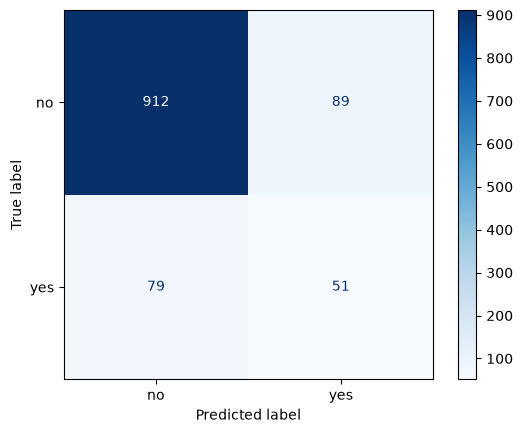

In [269]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Using scikit-learn for these metrics...

# Accuracy
# Generate predictions on the test set
y_pred = lr.predict(X_test)

# Accuracy
print(f'Accuracy: {accuracy_score(y_test, y_pred)}')

# Recall / Sensitivity / True Positive Rate (TPR)
print(f'Recall / Sensitivity / True Positive Rate (TPR): {recall_score(y_test, y_pred)}')

# Precision
print(f'Precision: {precision_score(y_test, y_pred)}')

# Specificity / True Negative Rate (TNR) is not defined in scikit-learn

# F1 score
print(f'F1 score: {f1_score(y_test, y_pred)}')

# Look at the confusion matrix before changing the probability threshold...

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
class_names = ["no", "yes"]

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap=plt.cm.Blues)
plt.show();

In [270]:
# probability for the positive class
y_pred_proba = lr.predict_proba(X_test)[:, 1]

# ROC AUC
print(f"ROC AUC: {roc_auc_score(y_test, y_pred_proba)}")

ROC AUC: 0.7336471221086605


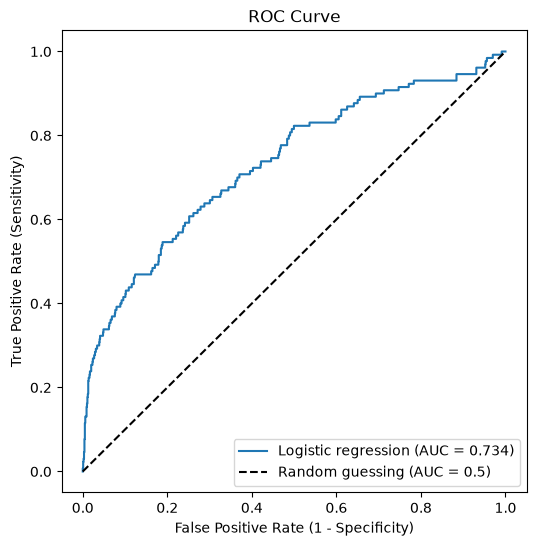

c:\Users\TALAL ALOTHMAN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


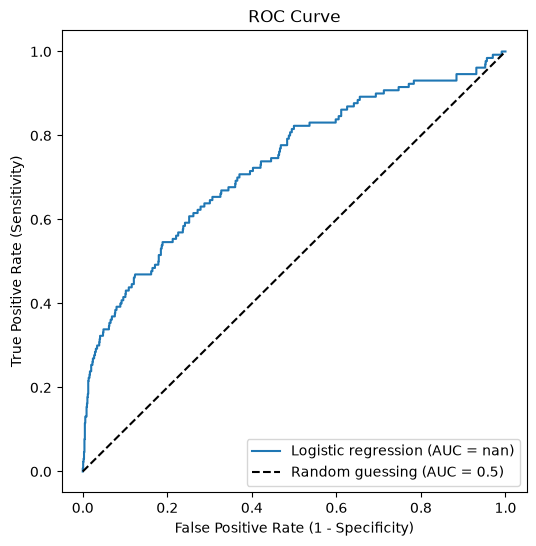

In [271]:
# Calculate ROC curve and ROC AUC score using correct variables and imports
# Calculate ROC curve and ROC AUC score using the correct positive-class probabilities
preds_proba1 = lr.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, preds_proba1, pos_label=1)
auc_score = roc_auc_score(y_test, preds_proba1)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()
auc_score = roc_auc_score(y_test == 'yes', preds_proba1)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

??

??

??

### 10. Interpret the Logistic Regression coefficients.

1. Extract the fitted Logistic Regression coefficients and convert them into **odds ratios** using:

```python
np.exp(coefficient)
```

2. Create a dataframe containing:

- feature name
- coefficient
- odds ratio

Then:

3. Sort the table by coefficient.
4. Identify features associated with higher odds of subscription.
5. Identify features associated with lower odds of subscription.
6. Interpret at least **two odds ratios** in words.

**Important:**
- Numerical variables were standardized, so a one-unit change for them means approximately a **one standard deviation increase**.
- One-hot encoded categorical variables are interpreted relative to the category that was dropped as the reference group.

In [272]:

# Extract feature names and coefficients
log_reg = lr  # use the trained LogisticRegression model
feature_names = X_train_smote.columns
coefficients = log_reg.coef_[0]
feature_names = X_train_smote.columns
coefficients = log_reg.coef_[0]

# Create dataframe
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Odds Ratio': np.exp(coefficients)
})

# Sort by coefficient
coef_df = coef_df.sort_values(
    by='Coefficient',
    ascending=False
)

coef_df

,Feature,Coefficient,Odds Ratio
26,poutcome_success,2.313362,10.108353
18,job_retired,0.943161,2.568086
34,month_mar,0.908572,2.480776
37,month_oct,0.865867,2.377065
11,education_secondary,0.736429,2.088464
12,education_tertiary,0.605475,1.832123
17,job_management,0.442447,1.556512
25,poutcome_other,0.295095,1.343255
21,job_student,0.237219,1.267718
14,job_blue-collar,0.210598,1.234416


In [273]:
# Higher odds of subscription
higher_odds = coef_df[coef_df['Odds Ratio'] > 1]

# Lower odds of subscription
lower_odds = coef_df[coef_df['Odds Ratio'] < 1]

print("Features associated with higher odds:")
print(higher_odds)

print("\nFeatures associated with lower odds:")
print(lower_odds)

Features associated with higher odds:
                Feature  Coefficient  Odds Ratio
26     poutcome_success     2.313362   10.108353
18          job_retired     0.943161    2.568086
34            month_mar     0.908572    2.480776
37            month_oct     0.865867    2.377065
11  education_secondary     0.736429    2.088464
12   education_tertiary     0.605475    1.832123
17       job_management     0.442447    1.556512
25       poutcome_other     0.295095    1.343255
21          job_student     0.237219    1.267718
14      job_blue-collar     0.210598    1.234416
8        marital_single     0.151529    1.163612
6              previous     0.076847    1.079877
2               default     0.050458    1.051753
24          job_unknown     0.007803    1.007834

Features associated with lower odds:
              Feature  Coefficient  Odds Ratio
5               pdays    -0.017660    0.982495
27   poutcome_unknown    -0.024461    0.975836
3             balance    -0.049834    0.951387
3

---

## K-Nearest Neighbors

### 11. Train a KNN classification model.

#### Part A: Train KNN models for different values of `k`

Run a KNN model for several odd values of `k` and capture the resulting metric you previously selected in a list.

Every loop iteration should:

1. Train a model with a specific `k` value.
2. Calculate the training score.
3. Calculate the testing score.
4. Create a dictionary storing `k`, the training score and the testing score.
5. Append the dictionary to a `scores` list.

You can test values such as:

```python
range(3, 22, 2)
```

In [274]:
# run a knn for various values of k, and capture the resulting accuracy scores in a list

# Every loop iteration should
# 1. train a model with a specific k value
# 2. calculate the training score
# 3. calculate the testing score
# 4. create a dictionary storing K, train score and  test score
# 5. append the dictionary in the scores list

scores = []

for k in range(3, 22, 2):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_smote, y_train_smote)
    train_score = model.score(X_train_smote, y_train_smote)
    test_score = model.score(X_test, y_test)
    test_score = model.score(X_test, y_test)
    score_dict = {'K': k, 'Train Score': train_score, 'Test Score': test_score}
    scores.append(score_dict)
    

#### Part B: Plot the results for the different values of `k`

1. In the same plot, graph the training and testing scores against `k`.
2. Choose a value of `k` that gives strong performance without a large gap between training and test values.

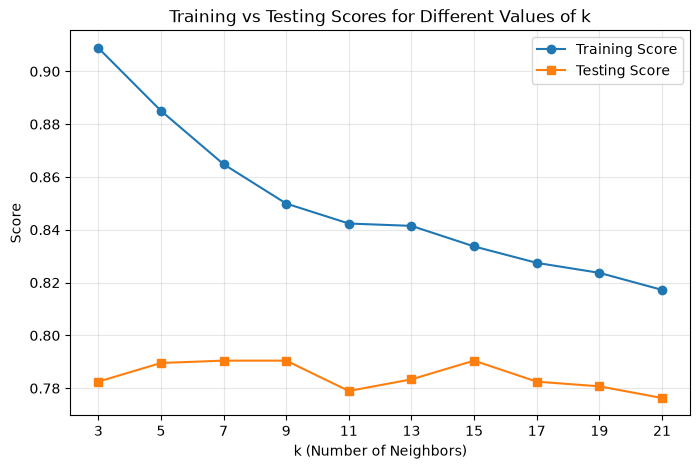

In [275]:
plt.figure(figsize=(8, 5))
k_values = [score['K'] for score in scores]
train_scores = [score['Train Score'] for score in scores]
test_scores = [score['Test Score'] for score in scores]
plt.plot(k_values, train_scores, marker='o', label='Training Score')
plt.plot(k_values, test_scores, marker='s', label='Testing Score')

plt.xlabel('k (Number of Neighbors)')
plt.ylabel('Score')
plt.title('Training vs Testing Scores for Different Values of k')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(k_values)
plt.show()

<Axes: xlabel='k', ylabel='test_score'>

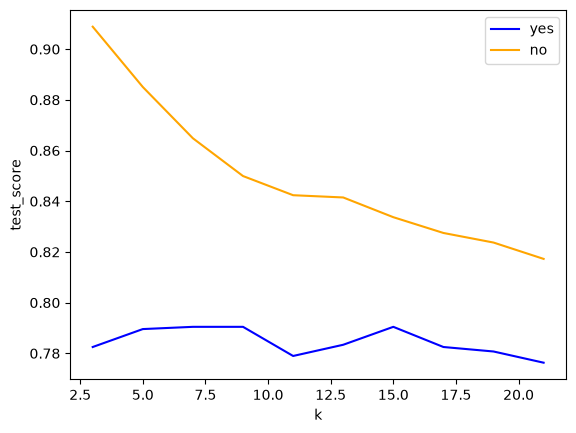

In [276]:
# Create a DataFrame from the existing scores list


# Plot
scores_df = pd.DataFrame(scores)
scores_df = scores_df.rename(columns={'K': 'k', 'Train Score': 'train_score', 'Test Score': 'test_score'})

sns.lineplot(data=scores_df, x='k', y='test_score', color='blue', label='yes')
sns.lineplot(data=scores_df, x='k', y='train_score', color='orange', label='no')

#### Part C:  Build the final KNN model.

Using the `k` value selected in Question 11:

1. Train your final KNN model

In [278]:
#TRAIN WITH K 21
knn = KNeighborsClassifier(n_neighbors=21)
# Train the final KNN model on the same encoded, balanced training set used for selection
knn.fit(X_train_smote, y_train_smote)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",21
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### 12. Evaluate the final KNN model.

Using the untouched test set, calculate the same metrics used for Logistic Regression:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC AUC

Also display:

1. The confusion matrix.
2. The ROC curve.

In [279]:
# run a knn for various values of k, and capture the resulting accuracy scores in a list

# Every loop iteration should
# 1. train a model with a specific k value
# 2. calculate the training score
# 3. calculate the testing score
# 4. create a dictionary storing K, train score and  test score
# 5. append the dictionary in the scores list

scores = []

for k in range(21):
    model = KNeighborsClassifier(n_neighbors=k)
    if k == 0:
        continue
    model.fit(X_train_smote, y_train_smote)
    train_score = model.score(X_train_smote, y_train_smote)
    test_score = model.score(X_test, y_test)
    test_score = model.score(X_test, y_test)
    score_dict = {'K': k, 'Train Score': train_score, 'Test Score': test_score}
    scores.append(score_dict)
    

Accuracy: 0.8514588859416445
Recall / Sensitivity / True Positive Rate (TPR): 0.3923076923076923
Precision: 0.36428571428571427
F1 score: 0.37777777777777777


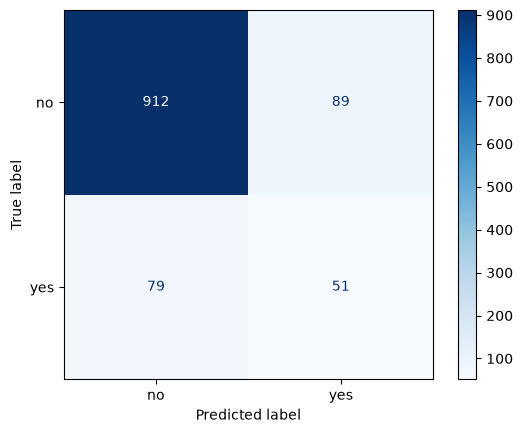

In [283]:


# Using scikit-learn for these metrics...

# Accuracy
# Generate predictions on the test set
y_pred = lr.predict(X_test)

# Accuracy
print(f'Accuracy: {accuracy_score(y_test, y_pred)}')

# Recall / Sensitivity / True Positive Rate (TPR)
print(f'Recall / Sensitivity / True Positive Rate (TPR): {recall_score(y_test, y_pred)}')

# Precision
print(f'Precision: {precision_score(y_test, y_pred)}')

# Specificity / True Negative Rate (TNR) is not defined in scikit-learn

# F1 score
print(f'F1 score: {f1_score(y_test, y_pred)}')

# Look at the confusion matrix before changing the probability threshold...

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
class_names = ["no", "yes"]

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap=plt.cm.Blues)
plt.show();


In [285]:
# probability for the positive class
y_pred_proba = lr.predict_proba(X_test)[:, 1]

# ROC AUC
print(f"ROC AUC: {roc_auc_score(y_test, y_pred_proba)}")

ROC AUC: 0.7336471221086605


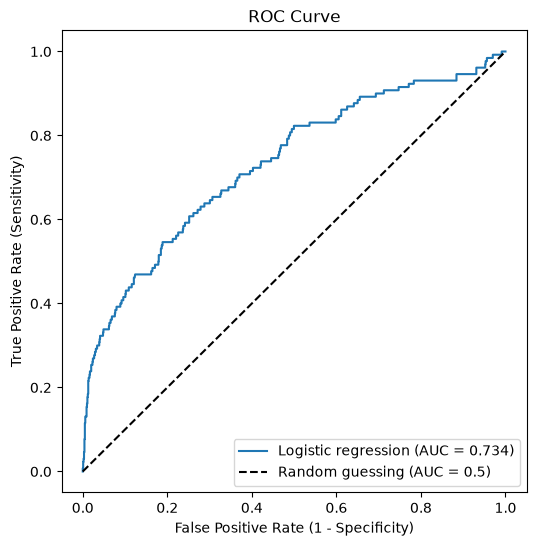

c:\Users\TALAL ALOTHMAN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


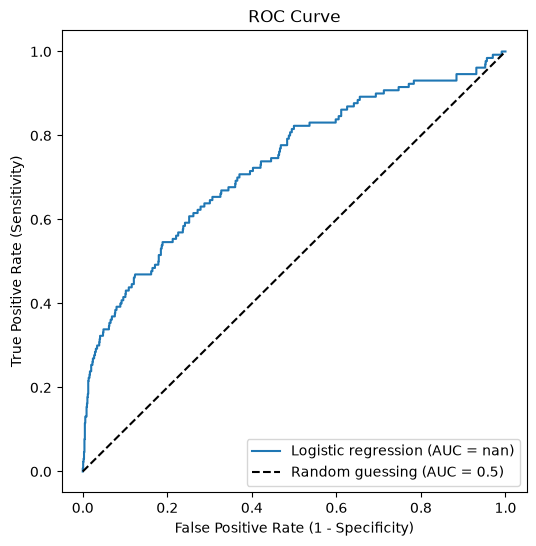

In [286]:
# Calculate ROC curve and ROC AUC score using correct variables and imports
# Calculate ROC curve and ROC AUC score using the correct positive-class probabilities
preds_proba1 = lr.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, preds_proba1, pos_label=1)
auc_score = roc_auc_score(y_test, preds_proba1)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()
auc_score = roc_auc_score(y_test == 'yes', preds_proba1)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

### 14. Compare the models and make a business recommendation.

Create a table comparing Logistic Regression and KNN using the test-set metrics.

Then answer:

1. Which model performs better for the business objective defined earlier?
2. What trade-off do you see between Precision and Recall?
3. Would you recommend Logistic Regression or KNN to the marketing team? Why?
4. Besides predictive performance, what advantage does Logistic Regression have when the business wants to understand **why** a client is more or less likely to subscribe?

Your recommendation should be based on the business objective — not simply on whichever model has the highest Accuracy.

In [287]:
from sklearn.metrics import balanced_accuracy_score



# Logistic Regression metrics
lr_y_pred = lr.predict(X_test)
lr_y_pred_proba = lr.predict_proba(X_test)[:, 1]

lr_accuracy = accuracy_score(y_test, lr_y_pred)
lr_balanced_accuracy = balanced_accuracy_score(y_test, lr_y_pred)
lr_precision = precision_score(y_test, lr_y_pred, zero_division=0)
lr_recall = recall_score(y_test, lr_y_pred)
lr_f1 = f1_score(y_test, lr_y_pred, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, lr_y_pred_proba)

# KNN metrics
knn_y_pred = knn.predict(X_test)
knn_y_pred_proba = knn.predict_proba(X_test)[:, 1]

knn_accuracy = accuracy_score(y_test, knn_y_pred)
knn_balanced_accuracy = balanced_accuracy_score(y_test, knn_y_pred)
knn_precision = precision_score(y_test, knn_y_pred, zero_division=0)
knn_recall = recall_score(y_test, knn_y_pred)
knn_f1 = f1_score(y_test, knn_y_pred, zero_division=0)
knn_roc_auc = roc_auc_score(y_test, knn_y_pred_proba)

comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN'],
    'Accuracy': [lr_accuracy, knn_accuracy],
    'Balanced Accuracy': [lr_balanced_accuracy, knn_balanced_accuracy],
    'Precision': [lr_precision, knn_precision],
    'Recall': [lr_recall, knn_recall],
    'F1 Score': [lr_f1, knn_f1],
    'ROC AUC': [lr_roc_auc, knn_roc_auc]
})
comparison_df = comparison_df.round(3)
comparison_df

comparison_df = comparison_df.round(3)
comparison_df


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.851,0.652,0.364,0.392,0.378,0.734
1,KNN,0.776,0.636,0.245,0.454,0.318,0.668


1- F1 prioretize both classes 

2-Precision measures the proportion of clients predicted to subscribe who actually subscribe, whereas Recall measures the proportion of actual subscribers correctly identified by the model. Increasing Recall may also increase false positives, meaning the marketing team contacts more clients who ultimately do not subscribe. Higher Precision reduces wasted contacts but may cause the model to miss some potential subscribers. The preferred balance depends on the cost of contacting clients and the value of acquiring new subscribers.

3-I would recommend the model that achieves stronger Recall while maintaining an acceptable Precision and F1 Score on the test set. If both models have comparable predictive performance, Logistic Regression would be a practical choice because it is easier to interpret and explain to the marketing team. However, if KNN demonstrates substantially better performance on the business's priority metric, its predictive advantage should also be considered before making the final decision.

4-Logistic Regression provides interpretable coefficients that can be converted into odds ratios. These indicate how changes in numerical features or differences between categorical groups are associated with the odds of subscribing, while holding other features constant. This helps the marketing team understand which factors are associated with a higher or lower likelihood of subscription and supports more transparent, evidence-based targeting decisions. KNN, in contrast, generally provides less direct insight into how individual features influence predictions.